In [2]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [3]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [4]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do Palete: {palete_comprimento} x {palete_largura}")
print(f"Dimensões da Caixa: {caixa_comprimento} x {caixa_largura}")

Dimensões do Palete: 8 x 6
Dimensões da Caixa: 3 x 2


In [5]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse=True) #garante que L >= W, já que o palete é retangular e o reverse=True garante que o maior valor seja L e o menor seja W
print(f"Dimensões classificadas do Palete: {L} x {W}")


Dimensões classificadas do Palete: 8 x 6


In [6]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True) #garante que l >= w, já que a caixa é retangular e o reverse=True garante que o maior valor seja l e o menor seja w
print(f"Dimensões classificadas da Caixa: {l_um} x {w_um}")


Dimensões classificadas da Caixa: 3 x 2


In [7]:

l_dois, w_dois = dimensoes_caixa[::-1] #rotaciona a caixa 90 graus
#ou
#l_dois, w_dois = w_um, l_um #rotaciona a caixa 90 graus

print(f"Dimensões classificadas da Caixa (rotacionada): {l_dois} x {w_dois}")

Dimensões classificadas da Caixa (rotacionada): 2 x 3


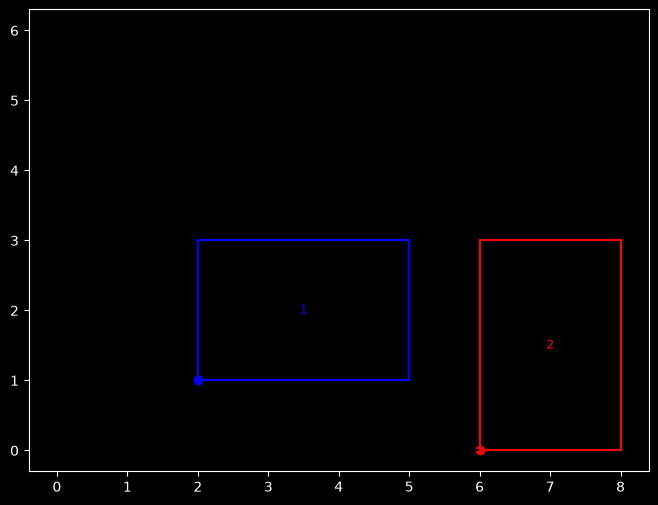

In [8]:
def plotar_caixa(botton_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = botton_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha='center', va='center')

def plotar_palete(L: int, W: int):
    plt.figure(figsize=(8, 6))#, facecolor='white')
    #ax = fig.add_subplot(111)
    #ax.set_facecolor('white')
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")

plotar_palete(L, W)
plotar_caixa(botton_left=[2, 1], l=3, w=2, color='blue', label='1')
plotar_caixa(botton_left=[6, 0], l=2, w=3, color='red', label='2')

In [9]:
f_um = lambda n_um, l_um, n_dois, l_dois: n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois: n_um * w_um + n_dois * w_dois

In [19]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2))   # p <= L - w_um
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3)) # q <= W - w_um

7
4


1 0
2 0
0 1
1 1
0 2
0 3


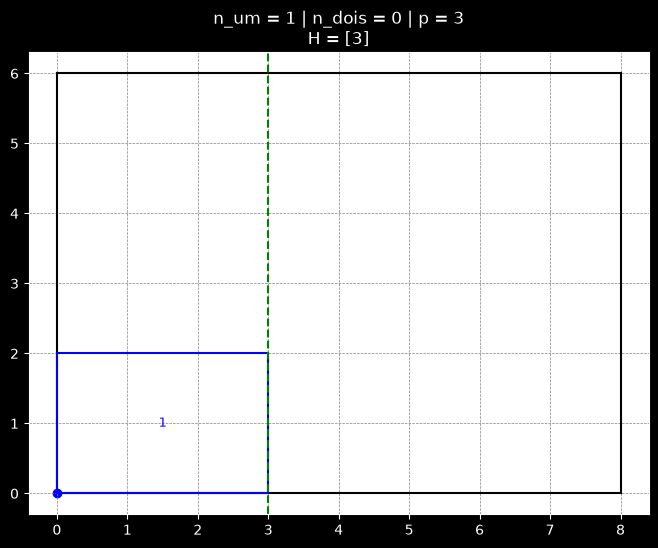

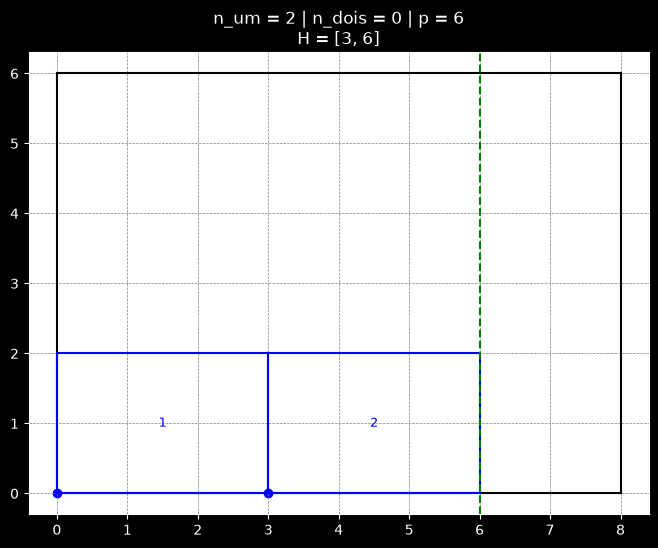

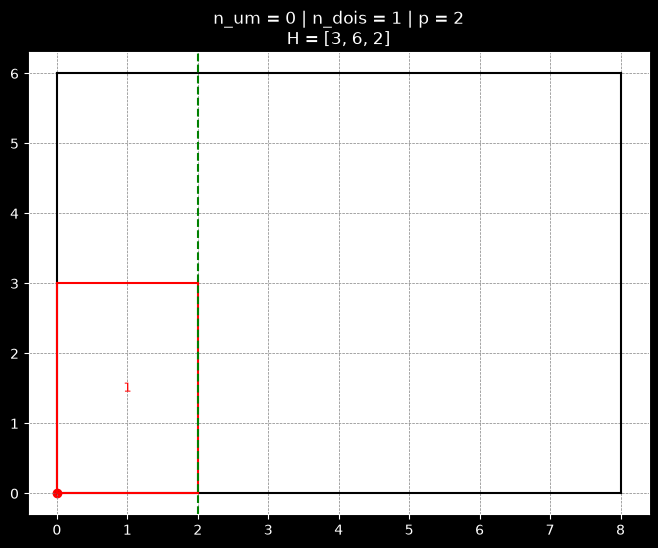

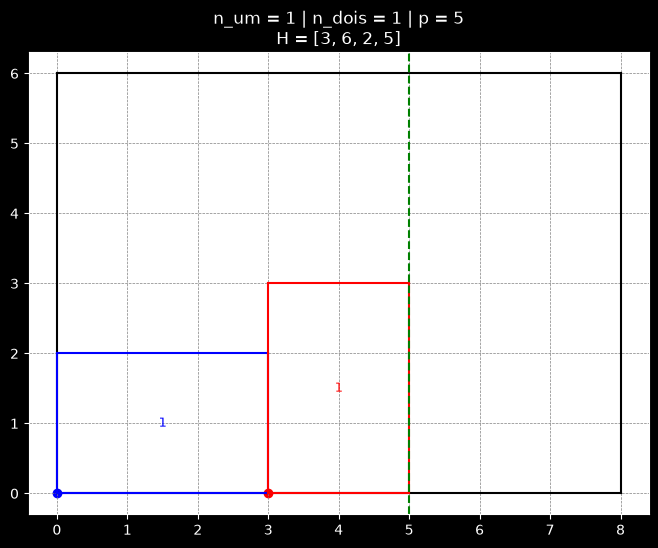

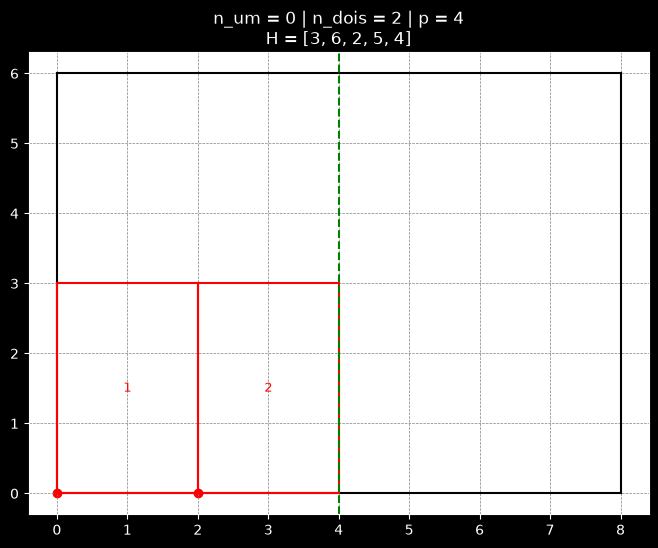

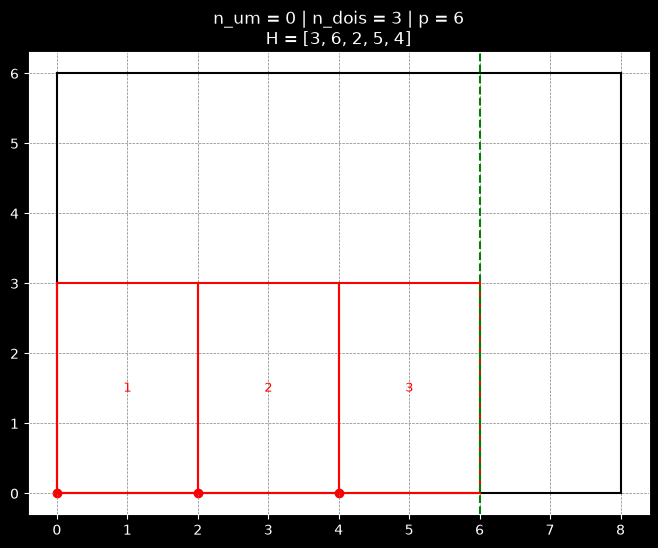

In [20]:
H = []
for n_dois, n_um in product(range(L), range(L)):
    #print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)

    if p <= L - w_um and p > 0:
        print(n_um, n_dois)
        if p not in H: #evitar duplicatas nos resultados
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(botton_left=[n*l_um, 0], l=l_um, w=w_um, color='blue', label=n + 1)

        for n in range(n_dois):
            plotar_caixa(botton_left=[n_um * l_um + n * l_dois, 0], l=l_dois, w=w_dois, color='red', label=n + 1)

        #print(n_um, n_dois, p)
        plt.axvline(x=p, color='green', linestyle='--')
        plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")
        plt.grid(color='gray', linestyle='--', linewidth=0.5)
        plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
        

In [ ]:
V = []
for n_dois, n_um in product(range(L), range(L)):
    #print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)

    if q <= W - w_um and q > 0:
        print(n_um, n_dois)
        if q not in V: #evitar duplicatas nos resultados
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(botton_left=[0, n*l_um], l=l_um, w=w_um, color='blue', label=n + 1)

        for n in range(n_dois):
            plotar_caixa(botton_left=[0, n_um * w_um + n * w_dois], l=l_dois, w=w_dois, color='red', label=n + 1)

        #print(n_um, n_dois, q)
        plt.axhline(y=q, color='green', linestyle='--')
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")
        plt.grid(color='gray', linestyle='--', linewidth=0.5)
        plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
      

In [24]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)

[2, 3, 4, 5, 6]
[2, 3, 4]
